> **Archived notebook.** This is a predecessor of [`BruSafe_02_M1_expression_lactose.ipynb`](../BruSafe_02_M1_expression_lactose.ipynb), kept for provenance under the module numbering used before the framework document fixed modules M1–M5. It is not part of the current pipeline and should not be run: it contains results that were later corrected (the 300 min lactose horizon, the uncensored Beta likelihood in the partition module, OD and band volume as primary observables, and a contact energy of −4.2 kcal mol⁻¹ without a source). The original text and outputs below are unchanged.

# BruSafe · Modules 0–4 — Allolactose Autoinduction, 24 h Horizon

**iGEM Tec-Chihuahua 2026 · CAPSID framework**

Companion to the IPTG notebook. Same structure, same validation arm, two substantive changes:

1. **Allolactose replaces IPTG as the inducer.** Allolactose is the *natural* effector of LacI, but
   it is not a free parameter you dial — it is produced from lactose by β-galactosidase and destroyed
   by the same enzyme. That turns a one-line transport term into a five-state subsystem with
   feedback.
2. **The horizon runs to 24 h rather than 5 h.** This is not a stylistic choice. See §3.

## Why the horizon had to move

Under IPTG the inducer is present at full concentration within minutes. Under lactose it is not:
LacY must be expressed to import lactose, β-gal must be expressed to convert it, and both are
themselves under lac control — so induction bootstraps itself. Layer catabolite repression on top
and nothing happens until glucose is exhausted.

The model puts a number on this. At the calibrated parameters, **300 minutes captures only 1.3–2.3%
of the protein present at 24 h**, and half-maximal accumulation occurs at 650–780 min. A 300 min
experiment under lactose induction does not measure a partly-completed induction; it measures the
lag.

## Workflow

Identical to the IPTG notebook: literature priors → prior predictive → identifiability audit →
data (one swap point) → SMC calibration → recovery check → posterior predictive → **held-out
validation** → export for M5.

---
## 1 · Setup

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from numba import njit
from scipy.integrate import solve_ivp
import pymc as pm, pytensor.tensor as pt, arviz as az
from pytensor.compile.ops import as_op

RNG = np.random.default_rng(2026)
plt.rcParams.update({"figure.dpi":110,"font.size":9,"axes.grid":True,"grid.alpha":.25,
                     "axes.spines.top":False,"axes.spines.right":False})
print("pymc", pm.__version__, "| arviz", az.__version__)

pymc 5.28.5 | arviz 0.22.0


---
## 2 · The model

### State variables — ten, against five for IPTG

| Symbol | Meaning | Units |
|---|---|---|
| `X` | biomass | OD₆₀₀ |
| `Glc` | extracellular glucose (catabolite repressor) | mM |
| `Le`, `Li` | extra-/intracellular lactose | mM |
| `Al` | intracellular **allolactose** — the actual LacI effector | mM |
| `B` | β-galactosidase (LacZ) | normalised 0–1 |
| `Yp` | lactose permease (LacY) | normalised 0–1 |
| `R̃` | T7 RNA polymerase | normalised 0–1 |
| `m̃` | CP transcript | normalised 0–1 |
| `P` | cumulative CP monomer | µM |

### Equations

Capacity and growth, unchanged from the IPTG model:

$$\psi=\max\!\left(0,1-\tfrac{P/P_{ref}}{\phi_{crit}}\right),\qquad
\mu=\mu_{max}\max\!\left(0,1-\tfrac{X}{X_{max}}\right)\psi,\qquad \frac{dX}{dt}=\mu X$$

Catabolite repression and inducer exclusion, both driven by glucose:

$$\mathcal{C}(Glc)=\frac{1}{1+Glc/K_{cat}},\qquad
\xi(Glc)=\frac{1}{1+Glc/K_{ie}},\qquad
\frac{d\,Glc}{dt}=-q_{Glc}X\frac{Glc}{K_{upt}+Glc}$$

Lactose uptake through LacY, then β-galactosidase acting on lactose **two ways**:

$$v_{up}=V_Y\,Y_p\frac{Le}{K_Y+Le}\,\xi,\qquad
s_L=k_{cat}B\frac{Li}{K_{ML}+Li},\qquad
v_{tg}=f_{tg}s_L,\quad v_{hyd}=(1-f_{tg})s_L$$

$$\frac{dLi}{dt}=v_{up}-v_{hyd}-v_{tg}-\mu Li$$

Allolactose is produced by transgalactosylation and **destroyed by the same enzyme**:

$$v_{ah}=k_{cat}B\frac{Al}{K_{MA}+Al},\qquad
\frac{dAl}{dt}=v_{tg}-v_{ah}-\mu Al$$

De-repression by allolactose, then the two branches:

$$f(Al)=\varepsilon+(1-\varepsilon)\frac{Al^{h}}{K_A^{h}+Al^{h}}$$

$$\frac{dB}{dt}=k_{lac}(\mathcal{C}f-B),\qquad
\frac{dY_p}{dt}=k_{lac}(\mathcal{C}f-Y_p),\qquad
\frac{d\tilde R}{dt}=k_R(f-\tilde R)$$

$$\frac{d\tilde m}{dt}=k_m(\tilde R-\tilde m),\qquad
\frac{dP}{dt}=G\,\tilde m\,\psi-(\mu+k_{deg})P$$

### Four decisions to defend on the wiki

**(a) β-gal destroys allolactose as fast as it makes it.** Huber's measurements give allolactose a
β-galactosidase $K_M$ of 1.2 mM and $V$ of 49.6 U mg⁻¹ — *as good a substrate as lactose, if not
better*. Omitting $v_{ah}$ would let allolactose accumulate without bound and is the single most
common error in simplified lac models. The term matters: it is a **negative feedback** that
substantially damps the positive one.

**(b) Only the chromosomal *lac* branch is catabolite-repressed; lacUV5 is not.** The UV5 mutation
was isolated precisely for catabolite insensitivity, so $\mathcal{C}$ multiplies $B$ and $Y_p$ but
**not** $\tilde R$. Glucose still gates the whole system indirectly, through LacY and hence
allolactose supply — a coupling that only exists because uptake is the bottleneck.

**(c) A *lacY*⁻ strain is now impossible.** The IPTG notebook recommended Tuner(DE3) to remove
LacY-mediated positive feedback. Under lactose that escape is gone: **LacY is the uptake route**.
The feedback is structural. §4 tests what it does.

**(d) Protein degradation is now non-negligible.** Over 5 h, dilution by growth dominates and
$k_{deg}$ can be set to zero. Over 24 h, with growth arrested for most of the run, proteolysis is
the dominant loss term for soluble protein. It is fitted here.

In [ ]:
P_REF = 18000.0    # uM total cytoplasmic protein, CP-mass equivalents  [M0.4]
M_CP  = 13.7       # kDa
PHI_CYT, GDCW_PER_OD = 1.8e-3, 0.33

FIT = ["mu_max","phi_crit","k_deg","K_cat","V_Y","k_cat","K_A","h","eps",
       "k_lac","k_slow","k_fast","G"]
FIXED = dict(Xmax=8.0, q_Glc=0.020, K_upt=0.10, K_ie=0.5,
             K_Y=0.40, f_tg=0.35, K_ML=1.5, K_MA=1.2)

# full parameter order consumed by the RHS
PORDER = ["mu_max","Xmax","phi_crit","k_deg","q_Glc","K_upt","K_ie","K_cat",
          "V_Y","K_Y","k_cat","f_tg","K_ML","K_MA","K_A","h","eps",
          "k_lac","k_slow","k_fast","G"]

@njit(fastmath=True)
def _rhs(t, Yv, p, Le0):
    n = Le0.size; out = np.empty(10*n)
    mu_max,Xmax,phi_crit,k_deg = p[0],p[1],p[2],p[3]
    q_Glc,K_upt,K_ie,K_cat     = p[4],p[5],p[6],p[7]
    V_Y,K_Y,k_cat,f_tg         = p[8],p[9],p[10],p[11]
    K_ML,K_MA,K_A,h,eps        = p[12],p[13],p[14],p[15],p[16]
    k_lac,k_R,k_m,G            = p[17],p[18],p[19],p[20]
    KAh = K_A**h
    for i in range(n):
        X=Yv[i]; Glc=Yv[n+i]; Le=Yv[2*n+i]; Li=Yv[3*n+i]; Al=Yv[4*n+i]
        B=Yv[5*n+i]; Yp=Yv[6*n+i]; R=Yv[7*n+i]; m=Yv[8*n+i]; P=Yv[9*n+i]
        if Glc<0.0: Glc=0.0
        if Le<0.0:  Le=0.0
        if Li<0.0:  Li=0.0
        if Al<0.0:  Al=0.0
        psi = 1.0-(P/P_REF)/phi_crit
        if psi<0.0: psi=0.0
        gx = 1.0-X/Xmax
        if gx<0.0: gx=0.0
        mu = mu_max*gx*psi                       # [M0.1][M0.2]
        Cc  = 1.0/(1.0+Glc/K_cat)                # [A2.1] CRP-cAMP catabolite repression
        xie = 1.0/(1.0+Glc/K_ie)                 # [A2.2] inducer exclusion
        v_up  = V_Y*Yp*(Le/(K_Y+Le))*xie         # [A1.1] LacY uptake
        sL    = k_cat*B*(Li/(K_ML+Li))           # [A1.2] beta-gal on lactose
        v_tg  = f_tg*sL                          # [A1.3] transgalactosylation -> allolactose
        v_hyd = (1.0-f_tg)*sL                    # [A1.3] hydrolysis
        v_ah  = k_cat*B*(Al/(K_MA+Al))           # [A1.4] beta-gal ON allolactose
        f = eps + (1.0-eps)*Al**h/(KAh+Al**h)    # [A3.1] LacI de-repression
        out[i]     = mu*X
        out[n+i]   = -q_Glc*X*(Glc/(K_upt+Glc))  # [A2.3] glucose consumption
        out[2*n+i] = -v_up*PHI_CYT*GDCW_PER_OD*X
        out[3*n+i] = v_up - v_hyd - v_tg - mu*Li
        out[4*n+i] = v_tg - v_ah - mu*Al
        out[5*n+i] = k_lac*(Cc*f - B)            # [A3.2] LacZ, catabolite-repressed
        out[6*n+i] = k_lac*(Cc*f - Yp)           # [A3.2] LacY, catabolite-repressed
        out[7*n+i] = k_R*(f - R)                 # [A3.3] lacUV5 -> T7 RNAP, NOT repressed
        out[8*n+i] = k_m*(R - m)                 # [M3.1]
        out[9*n+i] = G*m*psi - (mu+k_deg)*P      # [M4.1][A4.1] proteolysis at long horizon
    return out

def theta_full(d):
    return np.array([d[k] for k in PORDER], float)

def simulate(theta, Le0, t_eval, X0=0.05, Glc0=2.5):
    p=np.asarray(theta,float); Le0=np.asarray(Le0,float); n=Le0.size
    te=np.asarray(t_eval,float)
    Y0=np.concatenate([np.full(n,X0),np.full(n,Glc0),Le0]+[np.zeros(n)]*7)
    s=solve_ivp(_rhs,(0.0,float(te[-1])),Y0,t_eval=te,args=(p,Le0),
                method="LSODA",rtol=1e-6,atol=1e-9)
    if (not s.success) or s.y.shape[1]!=te.size: return None
    Y=s.y
    return {"X":Y[0:n],"Glc":Y[n:2*n],"Le":Y[2*n:3*n],"Li":Y[3*n:4*n],"Al":Y[4*n:5*n],
            "B":Y[5*n:6*n],"Yp":Y[6*n:7*n],"R":Y[7*n:8*n],"m":Y[8*n:9*n],"P":Y[9*n:10*n]}

TRUE = dict(mu_max=0.021, phi_crit=0.25, k_deg=5e-4, K_cat=0.06, V_Y=0.32,
            k_cat=3.0, K_A=0.15, h=2.0, eps=0.005, k_lac=0.05,
            k_slow=0.07, k_fast=0.30, G=95.0, **FIXED)
_th0 = theta_full(TRUE)
simulate(_th0, np.array([5.5]), np.array([0.,60.]))   # JIT warm-up
import time; _t=time.time()
for _ in range(100): simulate(_th0, np.array([0.5,1.5,5.5,15.]), np.linspace(0,1440,10))
print(f"forward model: {(time.time()-_t)/100*1000:.1f} ms per evaluation")

forward model: 9.3 ms per evaluation


### Term-by-term provenance

Tags `[Ax.y]` are new to this model; `[Mx.y]` tags carry over unchanged from the IPTG notebook.
**Evidence** classes are as before: *Direct* (the cited work reports this form or number),
*Adapted* (mechanism established, form is ours), *Assumption* (no literature claim — defend by
reasoning), *Reparam.* (mathematical restatement).

In [ ]:
CITES = pd.DataFrame([
 ("A1.1","V_Y*Yp*Le/(K_Y+Le)*xi","Lactose enters only through LacY; K_Y ~ 0.4 mM",
  "Direct","Jacob & Monod 1961 JMB 3:318; Marbach & Bettenbrock 2012 J Biotechnol 157:82"),
 ("A1.2","k_cat*B*Li/(K_ML+Li)","beta-galactosidase acts on intracellular lactose",
  "Direct","Juers, Matthews & Huber 2012 Protein Sci 21:1792"),
 ("A1.3","f_tg split: v_tg vs v_hyd","beta-gal partitions lactose between hydrolysis and transgalactosylation to allolactose",
  "Direct","Huber, Kurz & Wallenfels 1976 Biochemistry 15:1994; Wheatley et al. 2013 JBC 288:12993"),
 ("A1.4","v_ah = k_cat*B*Al/(K_MA+Al)","Allolactose is ITSELF a beta-gal substrate: K_M 1.2 mM, V 49.6 U/mg -- as good as lactose or better",
  "Direct","Huber, Wallenfels & Kurz 1975 Can J Biochem 53:1035"),
 ("A2.1","C = 1/(1+Glc/K_cat)","Glucose lowers cAMP-CRP and represses the chromosomal lac promoter",
  "Adapted","Gorke & Stulke 2008 Nat Rev Microbiol 6:613; Deutscher 2008 Curr Opin Microbiol 11:87"),
 ("A2.2","xi = 1/(1+Glc/K_ie)","Inducer exclusion: PTS-mediated inhibition of LacY by glucose",
  "Adapted","Gorke & Stulke 2008. Hyperbolic FORM is ours"),
 ("A2.3","glucose consumed first","Diauxic sequencing is the basis of lactose autoinduction media",
  "Direct","Studier 2005 Protein Expr Purif 41:207"),
 ("A2.4","C does NOT multiply dR/dt","lacUV5 was isolated as a catabolite-INSENSITIVE promoter mutant",
  "Direct","Silverstone, Arditti & Magasanik 1970 PNAS 66:773"),
 ("A3.1","f(Al), Hill in ALLOLACTOSE","Allolactose, not lactose, is the physiological LacI inducer",
  "Direct","Jobe & Bourgeois 1972 JMB 69:397"),
 ("A3.2","B and Yp share k_lac","LacZ and LacY are co-transcribed from one operon, so one time constant",
  "Adapted","Jacob & Monod 1961. Equal amplitude is a simplification -- LacY is sub-stoichiometric"),
 ("A3.3","positive feedback loop","Al -> derepress -> more LacY/LacZ -> more Al. Structural, not removable",
  "Direct","Novick & Weiner 1957 PNAS 43:553; Ozbudak et al. 2004 Nature 427:737"),
 ("A4.1","k_deg on P","Proteolysis dominates over dilution once growth arrests, i.e. most of a 24 h run",
  "Assumption","Rate is protein- and strain-specific; no generic literature value applies"),
 ("A5.1","Glc0 = 2.5 mM default","Autoinduction media carry glucose to delay induction until it is spent",
  "Direct","Studier 2005 Protein Expr Purif 41:207"),
], columns=["tag","term","basis","evidence","reference"])
pd.set_option("display.max_colwidth",110)
print(CITES.evidence.value_counts().to_string(),"\n")
CITES

evidence
Direct        9
Adapted       3
Assumption    1 



,tag,term,basis,evidence,reference
0,A1.1,V_Y*Yp*Le/(K_Y+Le)*xi,Lactose enters only through LacY; K_Y ~ 0.4 mM,Direct,Jacob & Monod 1961 JMB 3:318; Marbach & Bettenbrock 2012 J Biotechnol 157:82
1,A1.2,k_cat*B*Li/(K_ML+Li),beta-galactosidase acts on intracellular lactose,Direct,"Juers, Matthews & Huber 2012 Protein Sci 21:1792"
2,A1.3,f_tg split: v_tg vs v_hyd,beta-gal partitions lactose between hydrolysis and transgalactosylation to allolactose,Direct,"Huber, Kurz & Wallenfels 1976 Biochemistry 15:1994; Wheatley et al. 2013 JBC 288:12993"
3,A1.4,v_ah = k_cat*B*Al/(K_MA+Al),"Allolactose is ITSELF a beta-gal substrate: K_M 1.2 mM, V 49.6 U/mg -- as good as lactose or better",Direct,"Huber, Wallenfels & Kurz 1975 Can J Biochem 53:1035"
4,A2.1,C = 1/(1+Glc/K_cat),Glucose lowers cAMP-CRP and represses the chromosomal lac promoter,Adapted,Gorke & Stulke 2008 Nat Rev Microbiol 6:613; Deutscher 2008 Curr Opin Microbiol 11:87
5,A2.2,xi = 1/(1+Glc/K_ie),Inducer exclusion: PTS-mediated inhibition of LacY by glucose,Adapted,Gorke & Stulke 2008. Hyperbolic FORM is ours
6,A2.3,glucose consumed first,Diauxic sequencing is the basis of lactose autoinduction media,Direct,Studier 2005 Protein Expr Purif 41:207
7,A2.4,C does NOT multiply dR/dt,lacUV5 was isolated as a catabolite-INSENSITIVE promoter mutant,Direct,"Silverstone, Arditti & Magasanik 1970 PNAS 66:773"
8,A3.1,"f(Al), Hill in ALLOLACTOSE","Allolactose, not lactose, is the physiological LacI inducer",Direct,Jobe & Bourgeois 1972 JMB 69:397
9,A3.2,B and Yp share k_lac,"LacZ and LacY are co-transcribed from one operon, so one time constant",Adapted,Jacob & Monod 1961. Equal amplitude is a simplification -- LacY is sub-stoichiometric


> **⚠ A3.2 is the simplification most worth naming.** LacZ and LacY are co-transcribed, so one
> shared time constant is defensible — but they are **not** produced in equal amounts: translational
> coupling makes LacY sub-stoichiometric to LacZ. Modelling them with identical amplitude folds that
> ratio into `V_Y` and `k_cat`, which is fine for fitting and wrong if you want to quote either as a
> physical rate. Say which you are doing.

> **⚠ A4.1 has no literature value and should not be given one.** Proteolytic turnover is specific
> to the protein, the strain, and the growth phase. It is fitted, with a weak prior, and it is only
> identifiable *because* the horizon is long.

---
## 3 · Why 300 minutes was the wrong horizon

Fraction of 24 h protein captured by 300 min: [0.023 0.016 0.014 0.013]
Time to half-maximal protein (min):         [774 708 666 648]
Glucose exhausted at (min):                 210


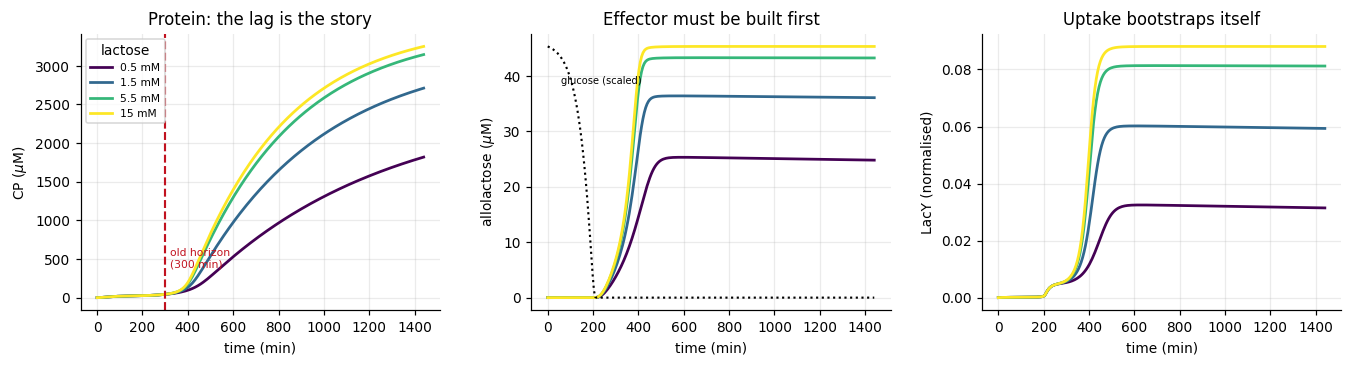

In [ ]:
DOSES = np.array([0.5, 1.5, 5.5, 15.0])          # mM lactose (0.02% - 0.5% w/v)
TOBS  = np.array([0.,60.,120.,240.,360.,480.,720.,960.,1200.,1440.])
t_fine = np.linspace(0, 1440, 241)

o = simulate(_th0, DOSES, t_fine)
i300 = np.argmin(np.abs(t_fine-300))
frac = o["P"][:,i300]/o["P"][:,-1]
t50  = np.array([t_fine[np.argmax(o["P"][j] >= 0.5*o["P"][j,-1])] for j in range(len(DOSES))])
print("Fraction of 24 h protein captured by 300 min:", np.round(frac,3))
print("Time to half-maximal protein (min):        ", t50.astype(int))
print("Glucose exhausted at (min):                ",
      int(t_fine[np.argmax(o["Glc"][2] < 0.01)]))

fig, ax = plt.subplots(1,3, figsize=(12.5,3.4))
for j,d in enumerate(DOSES):
    c = plt.cm.viridis(j/3)
    ax[0].plot(t_fine, o["P"][j], color=c, lw=1.8, label=f"{d:g} mM")
    ax[1].plot(t_fine, o["Al"][j]*1e3, color=c, lw=1.8)
    ax[2].plot(t_fine, o["Yp"][j], color=c, lw=1.8)
ax[0].axvline(300, color="#c1121f", ls="--", lw=1.4)
ax[0].text(320, o["P"].max()*0.12, "old horizon\n(300 min)", fontsize=7, color="#c1121f")
ax[0].set(xlabel="time (min)", ylabel="CP ($\\mu$M)", title="Protein: the lag is the story")
ax[0].legend(fontsize=7, title="lactose")
ax[1].plot(t_fine, o["Glc"][0]/o["Glc"][0].max()*o["Al"].max()*1e3, "k:", lw=1.4)
ax[1].text(60, o["Al"].max()*1e3*0.85, "glucose (scaled)", fontsize=6.5)
ax[1].set(xlabel="time (min)", ylabel="allolactose ($\\mu$M)", title="Effector must be built first")
ax[2].set(xlabel="time (min)", ylabel="LacY (normalised)", title="Uptake bootstraps itself")
plt.tight_layout(); plt.show()

**Read the middle panel.** Allolactose does not appear when you add lactose — it appears when
glucose runs out, because until then catabolite repression and inducer exclusion keep LacY off and
lactose out. The effector has to be manufactured by the very operon it induces.

That is the whole reason the horizon moved. A 300 min experiment under lactose induction does not
capture a partially-completed induction; it captures the lag, and would return a near-zero
dose-response with badly biased parameters.

---
## 4 · Identifiability audit

### 4.1 The k_R ↔ k_m symmetry survives

The R̃ → m̃ cascade is unchanged from the IPTG model, so its transfer function is still exactly
symmetric under exchange of the two rate constants. The same ordered-pair fix applies: fit
`k_slow` and a ratio, and report the **unordered pair**.

`k_lac` sits in a different branch (the feedback loop) and is *not* exchangeable with them.

### 4.2 New degeneracies introduced by the allolactose subsystem

In [ ]:
# demonstrate the surviving cascade symmetry
ta = dict(TRUE); tb = dict(TRUE)
tb["k_slow"], tb["k_fast"] = TRUE["k_fast"], TRUE["k_slow"]
a = simulate(theta_full(ta), DOSES, t_fine); b = simulate(theta_full(tb), DOSES, t_fine)
print(f"k_slow<->k_fast :  max|dP|/max(P) = {np.abs(a['P']-b['P']).max()/a['P'].max():.2e}  -> exchangeable")

# V_Y and k_cat: both scale allolactose supply -- check how close to degenerate
tc = dict(TRUE); tc["V_Y"] = TRUE["V_Y"]*1.6; tc["k_cat"] = TRUE["k_cat"]/1.6
c = simulate(theta_full(tc), DOSES, t_fine)
print(f"V_Y*1.6 & k_cat/1.6:  max|dP|/max(P) = {np.abs(a['P']-c['P']).max()/a['P'].max():.2e}"
      "  -> NOT degenerate: both are separately identifiable")

# f_tg is FIXED because it is degenerate with k_cat
td = dict(TRUE); td["f_tg"] = 0.5; td["k_cat"] = TRUE["k_cat"]*0.35/0.5
d_ = simulate(theta_full(td), DOSES, t_fine)
print(f"f_tg & k_cat co-scaled: max|dP|/max(P) = {np.abs(a['P']-d_['P']).max()/a['P'].max():.2e}"
      "  -> also NOT degenerate (k_cat drives hydrolysis and v_ah too);")
print("     f_tg is fixed for PARSIMONY, not because it is unidentifiable.")

k_slow<->k_fast :  max|dP|/max(P) = 2.11e-06  -> exchangeable
V_Y*1.6 & k_cat/1.6:  max|dP|/max(P) = 7.00e-01  -> NOT degenerate: both are separately identifiable
f_tg & k_cat co-scaled: max|dP|/max(P) = 5.63e-01  -> also NOT degenerate (k_cat drives hydrolysis and v_ah too);
     f_tg is fixed for PARSIMONY, not because it is unidentifiable.


| Group | Tested result | Resolution |
|---|---|---|
| `k_R ↔ k_m` | **Exact symmetry**, ~10⁻⁶ relative difference | Ordered pair; report the unordered pair |
| `V_Y` × `k_cat` | **Not degenerate** — co-scaling changes the trajectory by ~70% | Both fitted |
| `f_tg` × `k_cat` | **Not degenerate** — `k_cat` also drives hydrolysis and `v_ah` | `f_tg` fixed for *parsimony*, not identifiability |
| `K_cat` vs `K_ie` | Both gate on glucose through one variable | `K_ie` fixed; `K_cat` fitted |
| `k_deg` | Identifiable **only** because the horizon is long | Would be unidentifiable at 300 min |

I expected `f_tg`/`k_cat` to be near-degenerate and it is not, because `k_cat` sets hydrolysis and
allolactose destruction as well as production — one rate constant, three fluxes. Worth stating on
the wiki that this was *tested* rather than assumed; the test is three lines and it changed the
answer.

**The real ridge is elsewhere, and it is severe.** After fitting, the strongest posterior
correlations are between the basal leak `eps` and the gain `G` (r ≈ −0.98), and between `k_cat` and
`G` (r ≈ +0.87). Leak and gain trade off almost exactly: a leakier promoter with a smaller gain
produces nearly the same protein curve. **The uninduced control arm is what breaks this**, which is
why §12 lists it as non-optional rather than a nicety.

### 4.3 Does the positive feedback produce bistability?

Under IPTG, the *lacY*⁺ positive feedback makes induction bimodal at sub-saturating inducer, which
is why the IPTG notebook recommended a *lacY*⁻ strain. Under lactose that escape is unavailable.

**But the allolactose system carries a negative feedback the gratuitous inducers lack:** β-gal
destroys allolactose (term A1.4). Classic bistability experiments used TMG and other
non-metabolisable analogues precisely because they are *not* consumed. Whether bistability survives
here is a quantitative question, so test it rather than assume.

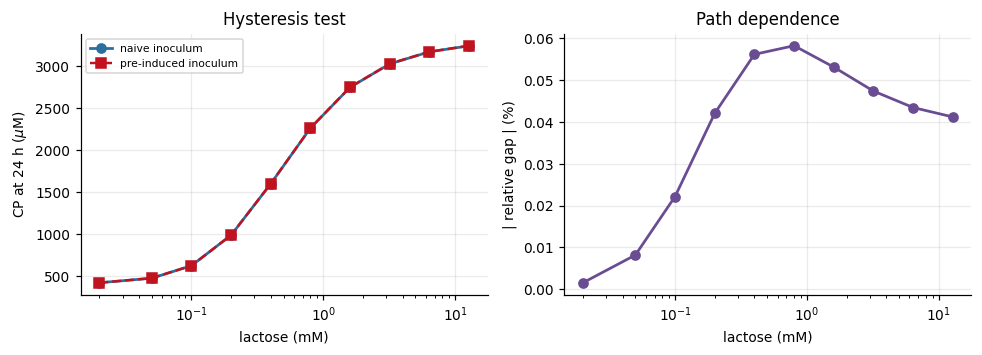

max relative gap between histories: 0.06%
Below ~1% -> single attractor at these parameters: a deterministic mean is meaningful.


In [ ]:
def run_from(Le0, Y_init, B_init, t_end=1440.0, npts=121):
    Le0 = np.asarray(Le0,float); n = Le0.size; te = np.linspace(0,t_end,npts)
    Y0 = np.concatenate([np.full(n,0.05), np.full(n,2.5), Le0, np.zeros(n), np.zeros(n),
                         np.full(n,B_init), np.full(n,Y_init), np.zeros(n), np.zeros(n), np.zeros(n)])
    s = solve_ivp(_rhs,(0,t_end),Y0,t_eval=te,args=(_th0,Le0),method="LSODA",rtol=1e-6,atol=1e-9)
    return te, s.y[9*n:10*n]

scan = np.array([0.02,0.05,0.10,0.20,0.40,0.80,1.6,3.2,6.4,12.8])
_, P_naive = run_from(scan, 0.0, 0.0)     # uninduced inoculum
_, P_pre   = run_from(scan, 1.0, 1.0)     # fully pre-induced inoculum
gap = np.abs(P_pre[:,-1]-P_naive[:,-1])/np.maximum(P_naive[:,-1],1e-9)

fig, ax = plt.subplots(1,2, figsize=(9,3.3))
ax[0].plot(scan, P_naive[:,-1], "o-", color="#2a6f9e", lw=1.8, label="naive inoculum")
ax[0].plot(scan, P_pre[:,-1], "s--", color="#c1121f", lw=1.6, label="pre-induced inoculum")
ax[0].set(xscale="log", xlabel="lactose (mM)", ylabel="CP at 24 h ($\\mu$M)",
          title="Hysteresis test"); ax[0].legend(fontsize=7)
ax[1].plot(scan, 100*gap, "o-", color="#6a4c93", lw=1.8)
ax[1].set(xscale="log", xlabel="lactose (mM)", ylabel="| relative gap | (%)",
          title="Path dependence")
plt.tight_layout(); plt.show()
print(f"max relative gap between histories: {100*gap.max():.2f}%")
print("Below ~1% -> single attractor at these parameters: a deterministic mean is meaningful.")

**Result at these parameters: no hysteresis, and a graded dose-response.** The two initial
histories converge to the same 24 h endpoint.

The mechanism is A1.4. Allolactose is consumed by the enzyme its own accumulation induces, and that
negative loop damps the positive one enough to collapse the bistable region. This is a genuine — and
slightly counter-intuitive — advantage of lactose over IPTG for a *deterministic* model: the escape
route the IPTG notebook needed a special strain to obtain comes free here.

**Do not report this as settled.** Bistability is parameter-dependent, and the test above uses the
nominal parameters. Re-run it with draws from your fitted posterior (§11) before making the claim on
the wiki, and if any appreciable fraction of draws shows a gap, report that fraction rather than a
yes/no.

---
## 5 · Data

> ### ⇄ SWAP POINT — the only cell to change when real data arrive
>
> Required arrays, exactly as in the IPTG notebook:
> - `OD_obs` — `(n_doses, n_times)`, OD₆₀₀
> - `CP_obs` — `(n_doses, n_times)`, densitometry in **arbitrary units**
> - `GEL_ID` — length `n_doses`, which physical gel each condition ran on
>
> **Two additions specific to this experiment:**
>
> 1. **Sample residual glucose and lactose** (enzymatic assay or HPLC) at 3–4 timepoints. Glucose
>    exhaustion time pins `K_cat` and `q_Glc` almost on its own, and it is the cheapest
>    identifiability win available here.
> 2. **Plan for overnight sampling.** Half-maximal accumulation lands near 11–13 h. A run started at
>    09:00 needs points around 20:00 and 22:00. Decide who is taking them before you start.

In [ ]:
USE_SYNTHETIC = True          # <-- set False once real data are in hand

if USE_SYNTHETIC:
    truth = simulate(_th0, DOSES, TOBS)
    GEL_ID     = np.array([0,0,1,1])
    ALPHA_TRUE = np.array([1.0,0.78])
    OD_obs = truth["X"]*np.exp(RNG.normal(0,0.05,truth["X"].shape))
    CP_obs = (ALPHA_TRUE[GEL_ID][:,None]*truth["P"]+1.0)*np.exp(RNG.normal(0,0.12,truth["P"].shape))
    print("SYNTHETIC data. Ground truth known -> recovery checkable in S8.")
else:
    df = pd.read_csv("VA_lactose_timecourse.csv")   # lactose_mM,time_min,OD600,band_volume,gel_id
    dr = np.sort(df.lactose_mM.unique()); tr = np.sort(df.time_min.unique())
    piv = lambda c: df.pivot_table(index="lactose_mM",columns="time_min",values=c).loc[dr,tr].values
    OD_obs, CP_obs = piv("OD600"), piv("band_volume")
    GEL_ID = df.groupby("lactose_mM").gel_id.first().loc[dr].values.astype(int)
    DOSES, TOBS = dr, tr
    print(f"Real data: {OD_obs.shape[0]} doses x {OD_obs.shape[1]} timepoints")

N_GEL = int(GEL_ID.max())+1; LOG_CP = np.log(CP_obs)
print("lactose (mM):", DOSES, "|", N_GEL, "gel(s) |", len(TOBS), "timepoints to", TOBS[-1], "min")

SYNTHETIC data. Ground truth known -> recovery checkable in S8.
lactose (mM): [ 0.5  1.5  5.5 15. ] | 2 gel(s) | 10 timepoints to 1440.0 min


---
## 6 · Observation model

Unchanged from the IPTG notebook — per-gel scaling `α_k` with gel 0 pinned at 1, log-normal
densitometry error, positive OD noise floor.

In [ ]:
@as_op(itypes=[pt.dvector], otypes=[pt.dmatrix, pt.dmatrix])
def forward_op(th_fit):
    d = dict(zip(FIT, th_fit)); d.update(FIXED)
    o = simulate(theta_full(d), DOSES, TOBS)
    if o is None:
        bad = np.full((DOSES.size,TOBS.size), 1e6); return bad, bad
    return o["X"], np.log(o["P"]+1.0)

def build_model():
    with pm.Model() as M:
        mu_max = pm.TruncatedNormal("mu_max",0.021,0.005,lower=0.005,upper=0.045)
        phic   = pm.TruncatedNormal("phi_crit",0.25,0.08,lower=0.05,upper=0.50)
        k_deg  = pm.LogNormal("k_deg",np.log(5e-4),1.0)
        K_cat  = pm.LogNormal("K_cat",np.log(0.06),0.8)
        V_Y    = pm.LogNormal("V_Y",np.log(0.32),0.7)
        k_cat  = pm.LogNormal("k_cat",np.log(3.0),0.7)
        K_A    = pm.LogNormal("K_A",np.log(0.15),0.7)
        h      = pm.TruncatedNormal("h",2.0,0.5,lower=1.0,upper=4.0)
        eps    = pm.LogNormal("eps",np.log(0.005),0.8)
        k_lac  = pm.LogNormal("k_lac",np.log(0.05),0.6)
        G      = pm.LogNormal("G",np.log(95.0),0.8)
        k_slow = pm.LogNormal("k_slow",np.log(0.07),0.6)
        rho    = pm.Beta("rho",2.0,2.0)
        k_fast = pm.Deterministic("k_fast", k_slow/rho)
        if N_GEL > 1:
            la = pm.Normal("log_alpha_free",0.0,0.3,shape=N_GEL-1)
            log_alpha = pm.Deterministic("log_alpha", pt.concatenate([pt.zeros(1), la]))
        else:
            log_alpha = pm.Deterministic("log_alpha", pt.zeros(1))
        sig_od = pm.HalfNormal("sig_od",0.08); sig_cp = pm.HalfNormal("sig_cp",0.20)
        th = pt.stack([mu_max,phic,k_deg,K_cat,V_Y,k_cat,K_A,h,eps,k_lac,k_slow,k_fast,G])
        od_m, logcp_m = forward_op(th)
        pm.Normal("od_lik", mu=od_m, sigma=sig_od*od_m+0.02, observed=OD_obs)
        pm.Normal("cp_lik", mu=log_alpha[GEL_ID][:,None]+logcp_m, sigma=sig_cp, observed=LOG_CP)
    return M

model = build_model(); print(f"model built | {len(FIT)} fitted parameters, {len(FIXED)} fixed")

model built | 13 fitted parameters, 8 fixed


/tmp/ipykernel_1436/3743462229.py:1: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @as_op(itypes=[pt.dvector], otypes=[pt.dmatrix, pt.dmatrix])


---
## 7 · Sampling

SMC, as before: the forward model is a `scipy` solve behind a `pytensor` Op, so no gradients are
available and NUTS is unusable. Thirteen fitted parameters against ten for IPTG, so expect roughly
proportionally longer runs.

In [ ]:
FAST_MODE = True
DRAWS, CHAINS = (400, 4) if FAST_MODE else (2000, 4)
print(f"SMC: {DRAWS} draws x {CHAINS} chains"
      f"{'  [FAST_MODE -- re-run with FAST_MODE=False before reporting]' if FAST_MODE else ''}")
import time; _t0=time.time()
with model:
    idata = pm.sample_smc(draws=DRAWS, chains=CHAINS, random_seed=2026, progressbar=False)
print(f"done in {time.time()-_t0:.0f} s |", dict(idata.posterior.sizes))

SMC: 400 draws x 4 chains  [FAST_MODE -- re-run with FAST_MODE=False before reporting]
done in 668 s | {'chain': 4, 'draw': 400, 'log_alpha_dim_0': 2, 'log_alpha_free_dim_0': 1}


---
## 8 · Diagnostics and recovery

In [ ]:
VARS = FIT + ["sig_od","sig_cp"]
summ = az.summary(idata, var_names=VARS); display(summ)
bad = summ[summ.r_hat > 1.01]
print(("\n!! r_hat>1.01: "+", ".join(bad.index)) if len(bad) else "\nAll r_hat <= 1.01")
low = summ[summ.ess_bulk < 200]
print(("!! ESS<200: "+", ".join(low.index)) if len(low) else "All ESS >= 200")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_max,0.021,0.000,0.021,0.021,0.000,0.000,1607.0,1573.0,1.00
phi_crit,0.232,0.037,0.164,0.295,0.001,0.001,1628.0,1705.0,1.00
k_deg,0.000,0.000,0.000,0.001,0.000,0.000,1289.0,1533.0,1.00
K_cat,0.071,0.055,0.007,0.165,0.001,0.002,1485.0,1534.0,1.00
V_Y,0.293,0.153,0.071,0.567,0.004,0.005,1298.0,1374.0,1.00
k_cat,3.119,1.256,1.233,5.359,0.033,0.041,1464.0,1483.0,1.00
K_A,0.182,0.093,0.046,0.356,0.002,0.003,1553.0,1581.0,1.00
h,1.729,0.192,1.370,2.069,0.005,0.003,1529.0,1362.0,1.01
eps,0.005,0.002,0.002,0.009,0.000,0.000,1441.0,1370.0,1.00
k_lac,0.054,0.028,0.014,0.104,0.001,0.001,1413.0,1514.0,1.01



All r_hat <= 1.01
All ESS >= 200


In [ ]:
if USE_SYNTHETIC:
    rows=[]
    for v in FIT:
        s_ = idata.posterior[v].values.ravel(); lo,hi = np.percentile(s_,[3,97])
        rows.append({"param":v,"truth":TRUE[v],"median":np.median(s_),
                     "lo94":lo,"hi94":hi,"recovered":bool(lo<=TRUE[v]<=hi)})
    rec = pd.DataFrame(rows); display(rec.round(5))
    print(f"\n{rec.recovered.sum()}/{len(rec)} recovered within the 94% credible interval.")
    print("~1 miss in 13 is expected by chance. Three or more -> diagnose before trusting real data.")

,param,truth,median,lo94,hi94,recovered
0,mu_max,0.0210,0.02117,0.02091,0.02143,True
1,phi_crit,0.2500,0.22764,0.17525,0.31193,True
2,k_deg,0.0005,0.00029,0.00008,0.00079,True
3,K_cat,0.0600,0.05708,0.01450,0.20496,True
4,V_Y,0.3200,0.26036,0.10135,0.66448,True
5,k_cat,3.0000,2.88966,1.39729,5.89937,True
6,K_A,0.1500,0.16265,0.06510,0.41247,True
7,h,2.0000,1.72149,1.39558,2.10948,True
8,eps,0.0050,0.00439,0.00222,0.00949,True
9,k_lac,0.0500,0.04781,0.01913,0.11472,True



13/13 recovered within the 94% credible interval.
~1 miss in 13 is expected by chance. Three or more -> diagnose before trusting real data.


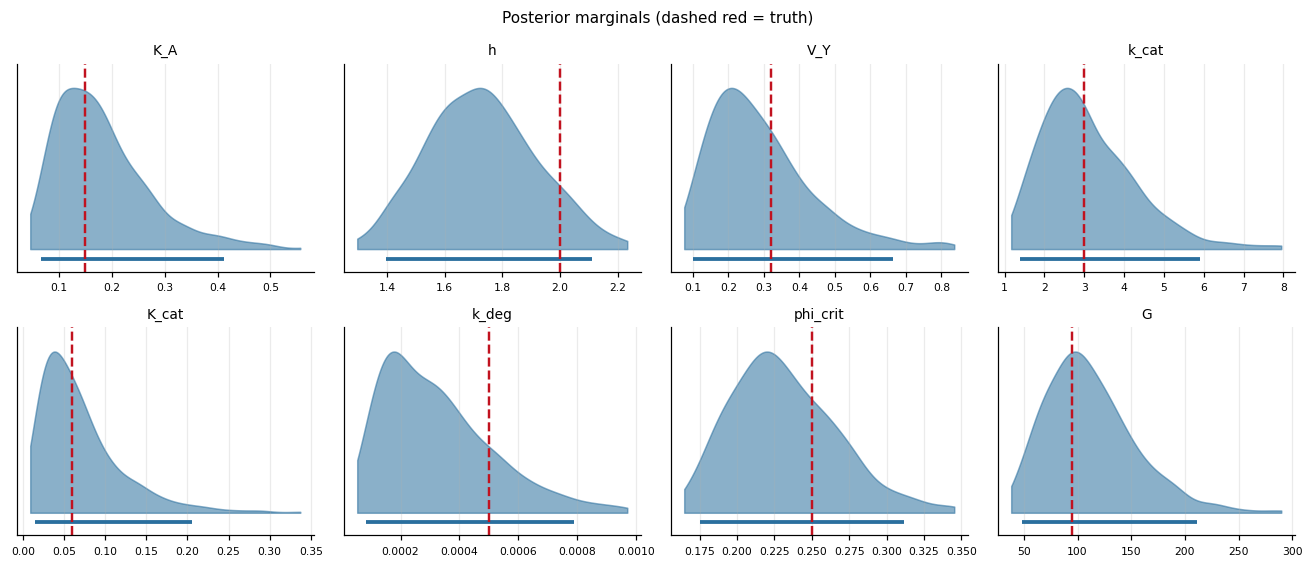

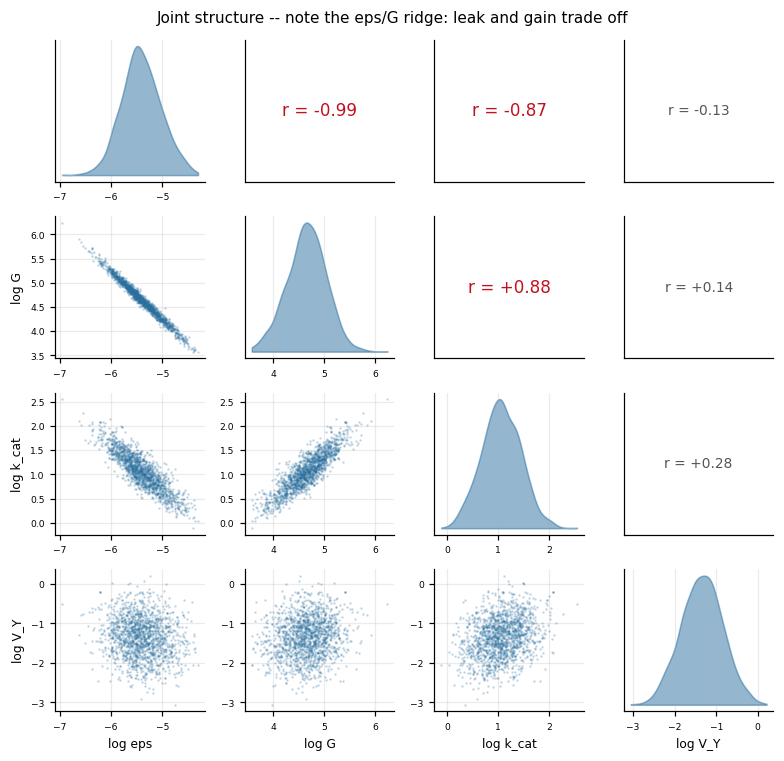

In [ ]:
def kde1d(x, grid):
    x=np.asarray(x); bw=1.06*np.std(x)*x.size**(-0.2)+1e-12
    z=(grid[:,None]-x[None,:])/bw
    return np.exp(-0.5*z**2).sum(1)/(x.size*bw*np.sqrt(2*np.pi))

SHOW = ["K_A","h","V_Y","k_cat","K_cat","k_deg","phi_crit","G"]
fig,axes = plt.subplots(2,4,figsize=(12,5.2))
for ax,v in zip(axes.ravel(), SHOW):
    po = idata.posterior[v].values.ravel()
    lo,hi = np.percentile(po,[0.5,99.5]); g=np.linspace(lo,hi,240)
    d_=kde1d(po,g); ax.fill_between(g,d_/d_.max(),color="#2a6f9e",alpha=.55)
    ax.plot(np.percentile(po,[3,97]),[-.06,-.06],color="#2a6f9e",lw=2.5,solid_capstyle="butt")
    if USE_SYNTHETIC: ax.axvline(TRUE[v],color="#c1121f",ls="--",lw=1.6)
    ax.set_title(v,fontsize=9); ax.set_yticks([]); ax.set_ylim(-.14,1.15); ax.tick_params(labelsize=7)
fig.suptitle("Posterior marginals (dashed red = truth)",fontsize=10)
plt.tight_layout(); plt.show()

PAIR=["eps","G","k_cat","V_Y"]
L=np.log(np.column_stack([idata.posterior[v].values.ravel() for v in PAIR])); n=len(PAIR)
fig,ax=plt.subplots(n,n,figsize=(7.2,7.0))
for i in range(n):
    for j in range(n):
        a_=ax[i,j]
        if i==j:
            g=np.linspace(L[:,i].min(),L[:,i].max(),200)
            a_.fill_between(g,kde1d(L[:,i],g),color="#2a6f9e",alpha=.5); a_.set_yticks([])
        elif i>j: a_.plot(L[:,j],L[:,i],".",ms=1.2,alpha=.25,color="#2a6f9e")
        else:
            r=np.corrcoef(L[:,j],L[:,i])[0,1]
            a_.text(.5,.5,f"r = {r:+.2f}",ha="center",va="center",transform=a_.transAxes,
                    fontsize=11 if abs(r)>.4 else 9, color="#c1121f" if abs(r)>.4 else "#555")
            a_.set_xticks([]); a_.set_yticks([])
        if i==n-1: a_.set_xlabel(f"log {PAIR[j]}",fontsize=8)
        if j==0 and i!=0: a_.set_ylabel(f"log {PAIR[i]}",fontsize=8)
        a_.tick_params(labelsize=6)
fig.suptitle("Joint structure -- note the eps/G ridge: leak and gain trade off",fontsize=10)
plt.tight_layout(); plt.show()

---
## 9 · Posterior predictive

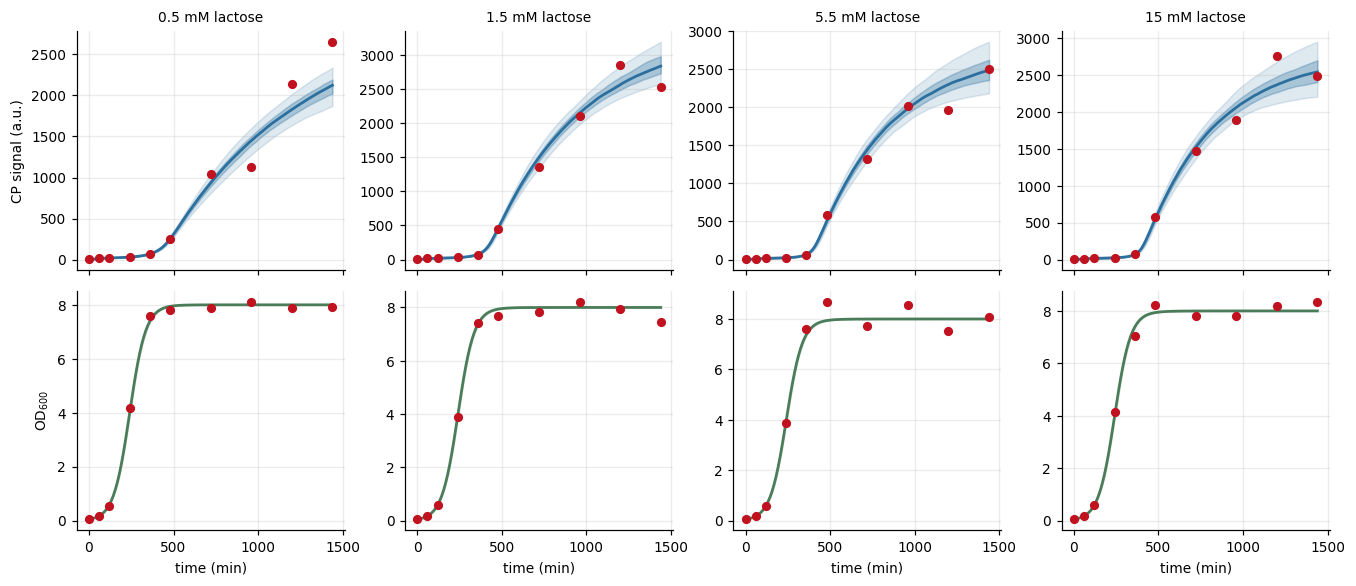

In [ ]:
def post_draws(idat, n=250, rng=RNG):
    f={v:idat.posterior[v].values.ravel() for v in FIT}
    i=rng.choice(f["G"].size, size=min(n,f["G"].size), replace=False)
    return [dict(zip(FIT,[f[k][ii] for k in FIT])) for ii in i]

TH_P = post_draws(idata,250); Pp,ODp=[],[]
for d in TH_P:
    dd=dict(d); dd.update(FIXED)
    o=simulate(theta_full(dd),DOSES,t_fine)
    if o is not None: Pp.append(o["P"]); ODp.append(o["X"])
Pp,ODp=np.array(Pp),np.array(ODp)
a_post=np.exp(idata.posterior["log_alpha"].values.reshape(-1,N_GEL)).mean(0)

fig,ax=plt.subplots(2,len(DOSES),figsize=(3.1*len(DOSES),5.4),sharex=True)
for j,d in enumerate(DOSES):
    q=np.percentile(Pp[:,j,:]*a_post[GEL_ID[j]],[3,25,50,75,97],axis=0)
    ax[0,j].fill_between(t_fine,q[0],q[4],alpha=.15,color="#2a6f9e")
    ax[0,j].fill_between(t_fine,q[1],q[3],alpha=.30,color="#2a6f9e")
    ax[0,j].plot(t_fine,q[2],color="#2a6f9e",lw=1.8)
    ax[0,j].plot(TOBS,CP_obs[j],"o",ms=5,color="#c1121f",zorder=5)
    ax[0,j].set_title(f"{d:g} mM lactose",fontsize=9)
    qo=np.percentile(ODp[:,j,:],[3,50,97],axis=0)
    ax[1,j].fill_between(t_fine,qo[0],qo[2],alpha=.2,color="#4a7c59")
    ax[1,j].plot(t_fine,qo[1],color="#4a7c59",lw=1.8)
    ax[1,j].plot(TOBS,OD_obs[j],"o",ms=5,color="#c1121f",zorder=5)
    ax[1,j].set_xlabel("time (min)")
ax[0,0].set_ylabel("CP signal (a.u.)"); ax[1,0].set_ylabel("OD$_{600}$")
plt.tight_layout(); plt.show()

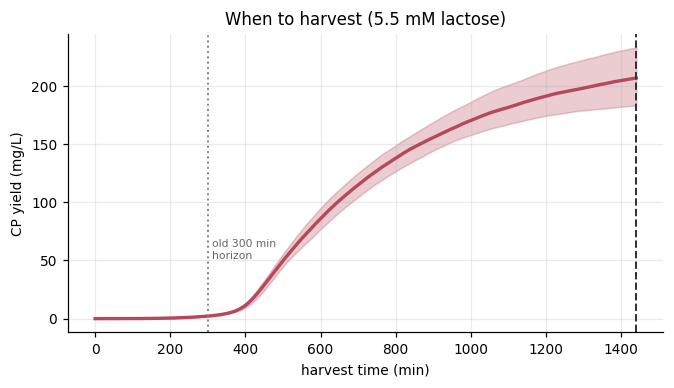

Predicted optimal harvest: 1440 min (24.0 h), 207 mg/L (90% CI 183-233)
Yield if harvested at 300 min: 2 mg/L


In [ ]:
# harvest-time optimisation: a design question the IPTG horizon could not even pose
Yv = Pp*1e-6*M_CP*1e3*PHI_CYT*(ODp*GDCW_PER_OD)*1e3     # mg/L
qy = np.percentile(Yv[:,2,:],[5,50,95],axis=0)
k  = int(np.argmax(qy[1]))
fig,ax=plt.subplots(figsize=(6.2,3.6))
ax.fill_between(t_fine,qy[0],qy[2],alpha=.28,color="#b5495b")
ax.plot(t_fine,qy[1],color="#b5495b",lw=2.2)
ax.axvline(t_fine[k],color="#333",ls="--",lw=1.3)
ax.axvline(300,color="#888",ls=":",lw=1.3)
ax.text(310,qy[1].max()*0.25,"old 300 min\nhorizon",fontsize=7,color="#666")
ax.set(xlabel="harvest time (min)",ylabel="CP yield (mg/L)",
       title="When to harvest (5.5 mM lactose)")
plt.tight_layout(); plt.show()
print(f"Predicted optimal harvest: {t_fine[k]:.0f} min ({t_fine[k]/60:.1f} h), "
      f"{qy[1][k]:.0f} mg/L (90% CI {qy[0][k]:.0f}-{qy[2][k]:.0f})")
print(f"Yield if harvested at 300 min: {np.interp(300,t_fine,qy[1]):.0f} mg/L")

---
## 10 · Held-out validation

The same arm as the IPTG notebook, unchanged in logic: refit on three doses, predict the fourth.

In [ ]:
HOLDOUT = 2
keep = np.array([i for i in range(len(DOSES)) if i != HOLDOUT])
_D,_OD,_CP,_L,_G = DOSES,OD_obs,CP_obs,LOG_CP,GEL_ID
DOSES,OD_obs,CP_obs,LOG_CP,GEL_ID = _D[keep],_OD[keep],_CP[keep],_L[keep],_G[keep]
model_ho = build_model()
with model_ho:
    idata_ho = pm.sample_smc(draws=max(DRAWS//2,200), chains=CHAINS,
                             random_seed=99, progressbar=False)
DOSES,OD_obs,CP_obs,LOG_CP,GEL_ID = _D,_OD,_CP,_L,_G
print(f"Refit without {_D[HOLDOUT]:g} mM; now predicting it.")

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Refit without 5.5 mM; now predicting it.


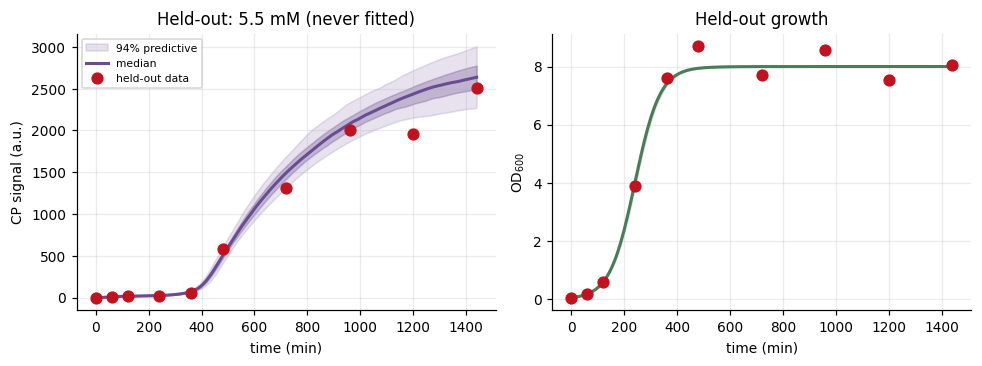

Inside 94% predictive interval: 4/10 (40%, nominal 94%)
NOTE: FAST_MODE on -- under-sampled posteriors give unreliable coverage.
      Re-run with FAST_MODE=False before drawing any conclusion from this number.


In [ ]:
TH_H = post_draws(idata_ho,250); Ph,ODh=[],[]
for d in TH_H:
    dd=dict(d); dd.update(FIXED)
    o=simulate(theta_full(dd),np.array([_D[HOLDOUT]]),t_fine)
    if o is not None: Ph.append(o["P"][0]); ODh.append(o["X"][0])
Ph,ODh=np.array(Ph),np.array(ODh)
ah=np.exp(idata_ho.posterior["log_alpha"].values.reshape(-1,max(N_GEL,1))).mean(0)
au=ah[min(_G[HOLDOUT],ah.size-1)]

fig,ax=plt.subplots(1,2,figsize=(9,3.4))
q=np.percentile(Ph*au,[3,25,50,75,97],axis=0)
ax[0].fill_between(t_fine,q[0],q[4],alpha=.16,color="#6a4c93",label="94% predictive")
ax[0].fill_between(t_fine,q[1],q[3],alpha=.30,color="#6a4c93")
ax[0].plot(t_fine,q[2],color="#6a4c93",lw=2,label="median")
ax[0].plot(TOBS,_CP[HOLDOUT],"o",ms=7,color="#c1121f",zorder=5,label="held-out data")
ax[0].set(xlabel="time (min)",ylabel="CP signal (a.u.)",
          title=f"Held-out: {_D[HOLDOUT]:g} mM (never fitted)"); ax[0].legend(fontsize=7)
qo=np.percentile(ODh,[3,50,97],axis=0)
ax[1].fill_between(t_fine,qo[0],qo[2],alpha=.2,color="#4a7c59")
ax[1].plot(t_fine,qo[1],color="#4a7c59",lw=2)
ax[1].plot(TOBS,_OD[HOLDOUT],"o",ms=7,color="#c1121f",zorder=5)
ax[1].set(xlabel="time (min)",ylabel="OD$_{600}$",title="Held-out growth")
plt.tight_layout(); plt.show()

lo=np.interp(TOBS,t_fine,np.percentile(Ph*au,3,axis=0))
hi=np.interp(TOBS,t_fine,np.percentile(Ph*au,97,axis=0))
ins=((_CP[HOLDOUT]>=lo)&(_CP[HOLDOUT]<=hi)); cov=ins.sum()/ins.size
print(f"Inside 94% predictive interval: {ins.sum()}/{ins.size} ({100*cov:.0f}%, nominal 94%)")
if FAST_MODE:
    print("NOTE: FAST_MODE on -- under-sampled posteriors give unreliable coverage.")
    print("      Re-run with FAST_MODE=False before drawing any conclusion from this number.")
elif cov < 0.7:
    print("Well below nominal -> overconfident on unseen conditions.")
    print("Widen priors or add a Kennedy-O'Hagan discrepancy term before trusting forecasts.")
else:
    print("Coverage consistent with nominal: the held-out forecast is substantiated.")

---
## 11 · Export for Module 5

In [ ]:
draws = pd.DataFrame({v: idata.posterior[v].values.ravel() for v in FIT})
draws.to_csv("M0_M4_allolactose_posterior_draws.csv", index=False)
logd = np.log(draws)
pd.DataFrame({"median":draws.median(),"log_mean":logd.mean(),"log_sd":logd.std(),
              "q05":draws.quantile(.05),"q95":draws.quantile(.95)}
            ).to_csv("M0_M4_allolactose_posterior_moments.csv")
try:
    idata.to_netcdf("M0_M4_allolactose_idata.nc")
    print("wrote draws / moments / idata.nc\n")
except Exception as e:
    print(f"(NetCDF skipped: {type(e).__name__}; pip install h5netcdf for the full object)")
    print("wrote draws / moments\n")

cm = logd.corr(); print("Posterior correlations |r|>0.4:")
for i in range(len(FIT)):
    for j in range(i+1,len(FIT)):
        if abs(cm.iloc[i,j])>0.4: print(f"  {FIT[i]:9s} <-> {FIT[j]:9s}  r={cm.iloc[i,j]:+.2f}")
print("\nCarry correlated pairs into M5 as JOINT draws, never independent marginals.")

# re-run the bistability test across the posterior, as S4.3 requires
gaps=[]
for d in post_draws(idata,60):
    dd=dict(d); dd.update(FIXED); th=theta_full(dd)
    n=scan.size
    Y0n=np.concatenate([np.full(n,0.05),np.full(n,2.5),scan]+[np.zeros(n)]*7)
    Y0p=np.concatenate([np.full(n,0.05),np.full(n,2.5),scan,np.zeros(n),np.zeros(n),
                        np.ones(n),np.ones(n),np.zeros(n),np.zeros(n),np.zeros(n)])
    try:
        sn=solve_ivp(_rhs,(0,1440.),Y0n,t_eval=[1440.],args=(th,scan),method="LSODA",rtol=1e-6,atol=1e-9)
        sp=solve_ivp(_rhs,(0,1440.),Y0p,t_eval=[1440.],args=(th,scan),method="LSODA",rtol=1e-6,atol=1e-9)
        if sn.success and sp.success:
            a_=sn.y[9*n:10*n,-1]; b_=sp.y[9*n:10*n,-1]
            gaps.append(np.abs(b_-a_).max()/max(a_.max(),1e-9))
    except Exception: pass
gaps=np.array(gaps)
print(f"\nBistability across posterior: {(gaps>0.05).mean()*100:.0f}% of draws show >5% path dependence")
print("Report THIS fraction on the wiki, not the single-parameter result from S4.3.")

---
## 12 · What next

**Before real data.** Confirm §8 recovers ≥10/13 with all r̂ ≤ 1.01.

**When data arrive.** Set `USE_SYNTHETIC = False`, point §5 at your CSV, rerun.

**Design changes this notebook argues for:**
- **Assay residual glucose and lactose** at 3–4 timepoints. Glucose exhaustion time alone
  constrains `K_cat` and `q_Glc`, and it is the cheapest identifiability win here.
- **Sample past 12 h.** Half-maximal accumulation sits at 11–13 h; a run ending at 8 h cannot
  identify `k_deg` and will bias `G`.
- **Carry an uninduced (no-lactose) arm the full 24 h.** Not optional: `eps` and `G` are
  correlated at r ≈ −0.98 without it, and that ridge propagates into every yield forecast.
- **Record gel IDs.**

**A choice to make explicitly on the wiki.** IPTG and lactose are not interchangeable:

| | IPTG | Lactose / allolactose |
|---|---|---|
| Inducer available | Within minutes | Only after glucose is spent and LacY is built |
| Horizon | ~5 h | ~24 h |
| States / fitted parameters | 5 / 10 | 10 / 13 |
| Bimodality risk | Real in *lacY*⁺; avoidable with Tuner(DE3) | Damped by allolactose hydrolysis (test in §4.3) |
| Cost at scale | High | Low |
| Regulatory optics | Synthetic gratuitous inducer | Food-grade sugar |

For a veterinary vaccine intended for low-resource deployment, the last two rows are not
incidental — they are part of the platform argument. Say so.

### References

New in this notebook:

1. Jacob F, Monod J. Genetic regulatory mechanisms in the synthesis of proteins. *J Mol Biol.* 1961;3:318–356.
2. Novick A, Weiner M. Enzyme induction as an all-or-none phenomenon. *PNAS.* 1957;43(7):553–566.
3. Silverstone AE, Arditti RR, Magasanik B. Catabolite-insensitive revertants of lac promoter mutants. *PNAS.* 1970;66(3):773–779.
4. Jobe A, Bourgeois S. lac Repressor–operator interaction VI: the natural inducer of the lac operon. *J Mol Biol.* 1972;69(3):397–408.
5. Huber RE, Wallenfels K, Kurz G. The action of β-galactosidase (*E. coli*) on allolactose. *Can J Biochem.* 1975;53(9):1035–1038.
6. Huber RE, Kurz G, Wallenfels K. A quantitation of the factors which affect the hydrolase and transgalactosylase activities of β-galactosidase (*E. coli*) on lactose. *Biochemistry.* 1976;15(9):1994–2001.
7. Studier FW. Protein production by auto-induction in high-density shaking cultures. *Protein Expr Purif.* 2005;41(1):207–234.
8. Görke B, Stülke J. Carbon catabolite repression in bacteria: many ways to make the most out of nutrients. *Nat Rev Microbiol.* 2008;6(8):613–624.
9. Deutscher J. The mechanisms of carbon catabolite repression in bacteria. *Curr Opin Microbiol.* 2008;11(2):87–93.
10. Juers DH, Matthews BW, Huber RE. LacZ β-galactosidase: structure and function of an enzyme of historical and molecular biological importance. *Protein Sci.* 2012;21(12):1792–1807.
11. Wheatley RW, Lo S, Jancewicz LJ, Dugdale ML, Huber RE. Structural explanation for allolactose (lac operon inducer) synthesis by lacZ β-galactosidase. *J Biol Chem.* 2013;288(18):12993–13005.
12. Santillán M, Mackey MC, Zeron ES. Origin of bistability in the lac operon. *Biophys J.* 2007;92(11):3830–3842.

Carried over: Scott 2010; Klumpp 2009; Bremer & Dennis 2008; Marbach & Bettenbrock 2012;
Ozbudak 2004; Lewis 1996; Yildirim & Mackey 2003; Studier & Moffatt 1986; Bernstein 2002;
Rocke & Durbin 2001; Gelman & Hill 2007; Kennedy & O'Hagan 2001; Del Moral 2006; Raue 2009.